# Анализ датасета Титаник
Данная работа - исследовательский анализ на базе датасета Титаника. Мы обработаем данные (null, выбросы), проанализируем как различные факторы связаны с выживаемостью пассажиров и попробуем объяснить, имеют ли найденные закономерности какой-то прикладной смысл.

Датасет можно рассматривать как базу клиентов, а выживаемость - как ключевую метрику, по которой сравниваются сегменты.

## Оглавление
1. Заполняем пропущенные значения
2. Обрабатываем выбросы
3. Делаем EDA
4. Смотрим, как связана вероятность выжить на Титанике с другими факторами
5. Оцениваем статистическую значимость различий
6. Итоговые выводы

## 1. Обработка пропущенных значений

Каждая колонка несет определенную информацию. Когда мы заполняем пропуски, главное - не исказить эту информацию, то есть не подставить на место пропусков неверные по смыслу значения. Например, если в колонке 80% пропусков и все их заполнить единицами, то единицы перевесят настоящие данные и дадут смещение. Мы хотим подставлять то, что имеет смысл и отражает реальное содержимое колонки.

### Как именно мы можем работать с пропущенными значениями?
- Удалять строки, если пропусков мало, а данных много, и эти строки не несут критической информации
- Заполнять средним, медианой или другими метриками по выборке (модой для категориальных переменных)
- Использовать методы вроде KNN, чтобы делать индивидуальное и более точное предсказание для каждой строки

У нас всего 891 строка, так что удалять строки из-за одного пропуска расточительно. Давайте попробуем понять, какие из остальных способов применимы к нашим данным.

In [1]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt
from scipy import stats
from sklearn.impute import KNNImputer
from sklearn.preprocessing import StandardScaler
from statsmodels.stats.proportion import proportions_ztest
import statsmodels.formula.api as smf

In [2]:
df = pd.read_csv("part_1.csv")
df.shape

(891, 12)

In [3]:
df.head(10)

,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
0,1,0,3,"Braund, Mr. Owen Harris",male,22.0,1,0,A/5 21171,7.2500,NaN,S
1,2,1,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",female,38.0,1,0,PC 17599,71.2833,C85,C
2,3,1,3,"Heikkinen, Miss. Laina",female,26.0,0,0,STON/O2. 3101282,7.9250,NaN,S
3,4,1,1,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",female,35.0,1,0,113803,53.1000,C123,S
4,5,0,3,"Allen, Mr. William Henry",male,35.0,0,0,373450,8.0500,NaN,S
5,6,0,3,"Moran, Mr. James",male,NaN,0,0,330877,8.4583,NaN,Q
6,7,0,1,"McCarthy, Mr. Timothy J",male,54.0,0,0,17463,51.8625,E46,S
7,8,0,3,"Palsson, Master. Gosta Leonard",male,2.0,3,1,349909,21.0750,NaN,S
8,9,1,3,"Johnson, Mrs. Oscar W (Elisabeth Vilhelmina Berg)",female,27.0,0,2,347742,11.1333,NaN,S
9,10,1,2,"Nasser, Mrs. Nicholas (Adele Achem)",female,14.0,1,0,237736,30.0708,NaN,C


In [4]:
# проверяем, нет ли полных дубликатов строк
df.duplicated().sum()

np.int64(0)

In [5]:
missing = pd.DataFrame({
    "пропусков": df.isnull().sum(),
    "доля, %": (df.isnull().mean() * 100).round(1),
})
missing[missing["пропусков"] > 0]

,пропусков,"доля, %"
Age,177,19.9
Cabin,687,77.1
Embarked,2,0.2


Как мы видим, больше всего пропусков в столбце с каютой - 77%. Также много пропусков в столбце с возрастом, почти 20%. В порте посадки пропущено всего 2 значения.

Разберем по очереди.

### 1.1. Каюта

Пропущено 687 значений из 891. Посмотрим, у кого именно нет номера каюты.

In [6]:
# доля пропусков в Cabin по классам билета
cabin_by_class = df.groupby("Pclass")["Cabin"].agg(
    пассажиров="size",
    без_каюты=lambda s: s.isnull().sum(),
)
cabin_by_class["доля пропусков, %"] = (cabin_by_class["без_каюты"] / cabin_by_class["пассажиров"] * 100).round(1)
cabin_by_class

,пассажиров,без_каюты,"доля пропусков, %"
Pclass,,,
1,216,40,18.5
2,184,168,91.3
3,491,479,97.6


В 1 классе каюта не указана у 18.5% пассажиров, во 2 классе у 91%, в 3 классе почти у всех - 97.6%. То есть те значения, что есть, в основном принадлежат пассажирам 1 класса.

Восстановить значения кают невозможно. Какие у нас вообще есть варианты?

1. Если брать моду, то выйдет, что все едут в 1 классе, еще и в одной каюте.
2. Если заполнять по классу билета, то мы столкнемся с тем, что у пассажиров 3 класса значений в этом столбце почти нет. Отталкиваться не от чего.
3. Столбец можно удалить, но только если в нем не осталось ничего полезного для анализа выживаемости.

Проверим третий пункт. Номер каюты начинается с буквы, например C85 или E46. Буква это палуба: на Титанике палубы обозначались буквами сверху вниз, от A до G. Палуба может сильно влиять на выживаемость, так как от нее напрямую зависит, как быстро человек мог попасть к спасательным шлюпкам.

Извлечем букву и посмотрим, есть ли связь с выживаемостью. Для пропусков поставим U - неизвестно.

In [7]:
df_clean = df.copy()

deck = df_clean["Cabin"].str[0].fillna("U").rename("Палуба")
df_clean.groupby(deck)["Survived"].agg(выживаемость="mean", пассажиров="count").round(2)

,выживаемость,пассажиров
Палуба,,
A,0.47,15
B,0.74,47
C,0.59,59
D,0.76,33
E,0.75,32
F,0.62,13
G,0.50,4
T,0.00,1
U,0.30,687


На первый взгляд связь есть. Там, где палуба известна, выживаемость 47-76%, а у U только 30%. Но U - это почти весь 2 и 3 класс, так что мы можем видеть просто влияние класса. Чтобы его убрать, посмотрим то же самое только для 1 класса.

In [8]:
first_class = df_clean["Pclass"] == 1
df_clean[first_class].groupby(deck[first_class])["Survived"].agg(выживаемость="mean", пассажиров="count").round(2)

,выживаемость,пассажиров
Палуба,,
A,0.47,15
B,0.74,47
C,0.59,59
D,0.76,29
E,0.72,25
T,0.00,1
U,0.48,40


Внутри 1 класса не все так однозначно:

- Строгого порядка нет. На самой верхней палубе A выжило 47%, а на С, которая ниже, 59%, а еще ниже - палуба D, процент снова поднимается до 76%.
- Стоит отметить что группы маленькие, от 15 до 59 человек, такие различия могут быть случайными.
- У кого каюта не записана, выживаемость 48%. Возможно, номера кают восстанавливали в том числе со слов выживших, и тогда пропуск это следствие того, что человек погиб, а не причина. По открытым источникам пассажиры 1 класса проживали на палубах от A до E (T в таблице это один пассажир), таким образом такое количество пассажиров не могло проживать где-то еще.

Гипотеза про близость к шлюпкам на этих данных не подтверждается, а различия между U и остальными, возможно, связаны с фактом выживания человека и последующим восстановлением его каюты, такие данные нельзя использовать для анализа, поэтому столбец Cabin удаляем.

In [9]:
df_clean = df_clean.drop(columns="Cabin")

In [10]:
df_clean.dtypes

PassengerId      int64
Survived         int64
Pclass           int64
Name               str
Sex                str
Age            float64
SibSp            int64
Parch            int64
Ticket             str
Fare           float64
Embarked           str
dtype: object

### 1.2. Возраст

Чтобы заполнить пропуски в возрасте, используем метод KNN. В отличие от простого заполнения модой, средним или медианным значением, этот метод позволит оценить примерный возраст каждого пассажира по похожим на него людям. В нашем анализе это очень важно, так как в дальнейшем будет проводиться анализ выживаемости в зависимости от возраста. Если заполнить 177 пропусков единственным числом, этот анализ будет некорректен.

Как именно делаем:

- Соседей ищем по классу билета, числу родственников на борту, цене билета и полу.
- Survived в признаки не берем. Это целевая переменная, если заполнять по ней возраст, а потом смотреть связь возраста с выживаемостью, мы сами эту связь и нарисуем.
- PassengerId тоже не берем, это просто порядковый номер.
- Перед KNN признаки масштабируем. Метод считает расстояния, и без масштабирования цена билета просто перевесит все остальное.

In [11]:
knn_features = ["Pclass", "SibSp", "Parch", "Fare", "Sex", "Age"]

X = df_clean[knn_features].copy()
X["Sex"] = (X["Sex"] == "male").astype(int)

scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

imputer = KNNImputer(n_neighbors=5)
X_filled = scaler.inverse_transform(imputer.fit_transform(X_scaled))

df_clean["Age"] = X_filled[:, knn_features.index("Age")]

Проверим, что заполнение не испортило распределение возраста.

In [12]:
pd.DataFrame({
    "до заполнения": df["Age"].describe(),
    "после заполнения": df_clean["Age"].describe(),
    "только заполненные": df_clean.loc[df["Age"].isnull(), "Age"].describe(),
}).round(2)

,до заполнения,после заполнения,только заполненные
count,714.00,891.00,177.00
mean,29.70,29.97,31.08
std,14.53,13.96,11.34
min,0.42,0.42,3.50
25%,20.12,21.15,24.80
50%,28.00,28.00,28.40
75%,38.00,38.00,38.60
max,80.00,80.00,56.00


Распределение почти не поменялось: среднее было 29.7, стало 30.0, медиана как была 28, так и осталась. Заполненные значения лежат от 3.5 до 56 лет, а не в одной точке, как было бы при заполнении медианой.

### 1.3. Порт посадки

Пропусков всего два. Порт - категориальный признак, среднего у него нет, поэтому заполняем модой, то есть самым частым значением.

In [13]:
df_clean["Embarked"] = df_clean["Embarked"].fillna(df_clean["Embarked"].mode()[0])

Пропусков больше нет. Можно переходить к выбросам.

## 2. Обрабатываем выбросы

Как и с пропусками, здесь нам важно не потерять информацию. Выброс это не обязательно ошибка.

В возрасте выбросы это просто пожилые люди, а в цене билета их много, но это реальные дорогие билеты 1 класса, и трогать их не нужно. Ниже показано, почему.

### Как определить, что значение - выброс?

- По квантилям, например, все, что выходит за 1.5 межквартильных размаха (IQR) от границ «ящика». Это то, что рисует boxplot.
- ML-методами для детекции аномалий, например DBSCAN.
- Конкретными правилами из предметной области, например «возраст не может быть больше 120».

Давайте для простоты будем использовать IQR, а как обработать - решать в зависимости от того, какую информацию несут найденные значения.

### Как обработать выбросы?

- Удаление, значения, помеченные как выбросы, удаляются. Нежелательно, так как приводит к потере данных.
- Винсоризация, значения не удаляются, а заменяются верхней границей boxplot или заданным перцентилем.
- Трансформация, применяется математическое преобразование, например логарифмирование. Так сохраняется иерархия данных (дорогие билеты все еще самые дорогие, дешевые - дешевые), а экстремальные значения прижимаются к центру распределения. Но мы меняем сам столбец. Теперь это не цена билета, а логарифм цены, это важно помнить.
- Дискретизация, перевод числа в категориальный признак, например «дешевый», «средний», «дорогой», «vip».

### Ищем выбросы

Смотрим boxplot для возраста и стоимости билета. Остальные признаки либо категориальные, либо текстовые. SibSp и Parch это число родственников на борту, большие значения там означают большие семьи, а не аномалии.

<Axes: >

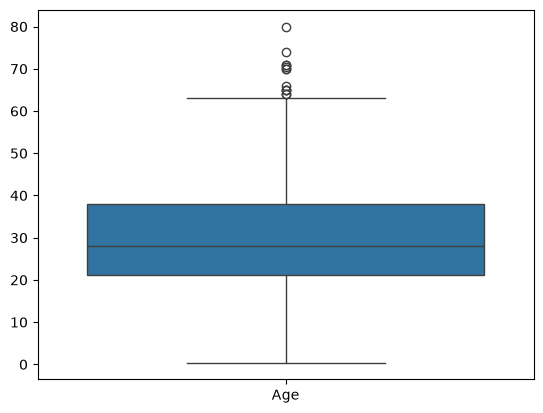

In [14]:
sns.boxplot([df_clean["Age"]])

В данном случае нет необходимости как-либо корректировать данные, потому что это естественное демографическое распределение.

<Axes: >

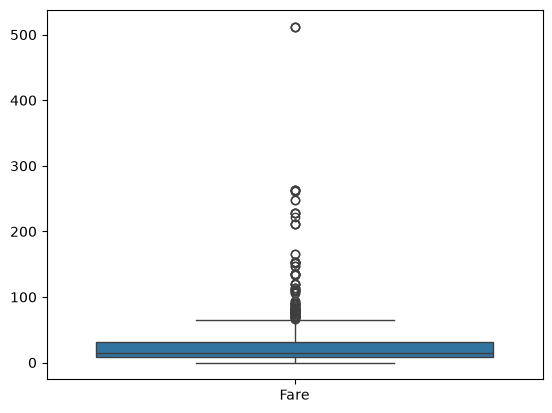

In [15]:
sns.boxplot([df_clean["Fare"]])

In [16]:
# Граница выбросов по IQR и классы пассажиров с билетами дороже нее
IQR = df_clean['Fare'].quantile(0.75) - df_clean['Fare'].quantile(0.25)
up_bound = df_clean['Fare'].quantile(0.75) + 1.5 * IQR
df_clean[df_clean['Fare'] > up_bound]['Pclass'].value_counts()

Pclass
1    104
3      7
2      5
Name: count, dtype: int64

Boxplot отмечает большое количество значений как выбросы в стоимости билетов. Но если посмотреть, видно, что это не ошибки сбора данных, а реальные цены на vip-билеты, те пассажиры 1 класса.

В данной задаче корректировать эти значения не следует. Они отражают статус и платежеспособность клиента, а это влияет на ключевую метрику.

Но в целях демонстрации покажем все четыре метода из списка выше. **В дальнейшем измененные данные использоваться не будут**.

In [17]:
# Метод винсоризации значения выше границы заменяем самой границей
df_winsor = df_clean.copy()
df_winsor["Fare"] = df_winsor["Fare"].clip(upper=up_bound)

In [18]:
# Метод удаления
df_drop = df_clean[df_clean["Fare"] <= up_bound].copy()

In [19]:
# Метод трансформации log(x + 1), так как есть билеты со стоимостью 0
df_log = df_clean.copy()
df_log["Fare_log"] = np.log1p(df_log["Fare"])

In [20]:
# Метод дискретизации
df_bins = df_clean.copy()
category = ["дешевый", "средний", "дорогой", "vip"]
df_bins["Fare_group"] = pd.qcut(df_bins["Fare"], q=4, labels=category)

In [21]:
pd.DataFrame({
    "исходный": df_clean["Fare"].describe(),
    "винсоризация": df_winsor["Fare"].describe(),
    "удаление": df_drop["Fare"].describe(),
    "логарифм": df_log["Fare_log"].describe(),
}).round(2)

,исходный,винсоризация,удаление,логарифм
count,891.00,891.00,775.00,891.00
mean,32.20,24.05,17.82,2.96
std,49.69,20.48,13.58,0.97
min,0.00,0.00,0.00,0.00
25%,7.91,7.91,7.90,2.19
50%,14.45,14.45,13.00,2.74
75%,31.00,31.00,26.00,3.47
max,512.33,65.63,65.00,6.24



Проанализируем таблицу:

- Винсоризация и удаление срезают максимум с 512 до 65, а среднее заметно падает. При удалении мы еще и теряем 116 строк.
- Логарифм никого не выкидывает, но сжимает шкалу. Максимум 6.24 при медиане 2.74.

Дальше работаем с исходным Fare

## 3. Исследовательский анализ данных (EDA)

Теперь посмотрим на данные целиком, описательные статистики, разброс и распределения.

In [22]:
num_cols = ["Survived", "Pclass", "Age", "SibSp", "Parch", "Fare"]
df_clean[num_cols].describe().round(2)

,Survived,Pclass,Age,SibSp,Parch,Fare
count,891.00,891.00,891.00,891.00,891.00,891.00
mean,0.38,2.31,29.97,0.52,0.38,32.20
std,0.49,0.84,13.96,1.10,0.81,49.69
min,0.00,1.00,0.42,0.00,0.00,0.00
25%,0.00,2.00,21.15,0.00,0.00,7.91
50%,0.00,3.00,28.00,0.00,0.00,14.45
75%,1.00,3.00,38.00,1.00,0.00,31.00
max,1.00,3.00,80.00,8.00,6.00,512.33


Что видно из таблицы:

- Выжило 38% пассажиров.
- Больше половины ехали 3 классом медиана Pclass равна 3.
- Средний возраст 30 лет, самому младшему меньше года, самому старшему 80.
- Медианная цена билета 14.45 при средней 32.2. Среднее больше медианы в два раза, значит есть длинный хвост дорогих билетов.
- Большинство ехали без семьи медианы SibSp и Parch равны нулю.

Теперь дисперсия.

In [23]:
df_clean[num_cols].var().sort_values(ascending=False).round(2)

Fare        2469.44
Age          194.79
SibSp          1.22
Pclass         0.70
Parch          0.65
Survived       0.24
dtype: float64

Наибольшей дисперсией обладает Fare это стоимость билета. Это логично, так как мы имеем дело со скошенным распределением большинство билетов дешевые, но есть хвост дорогих.
Посмотрим на распределения.

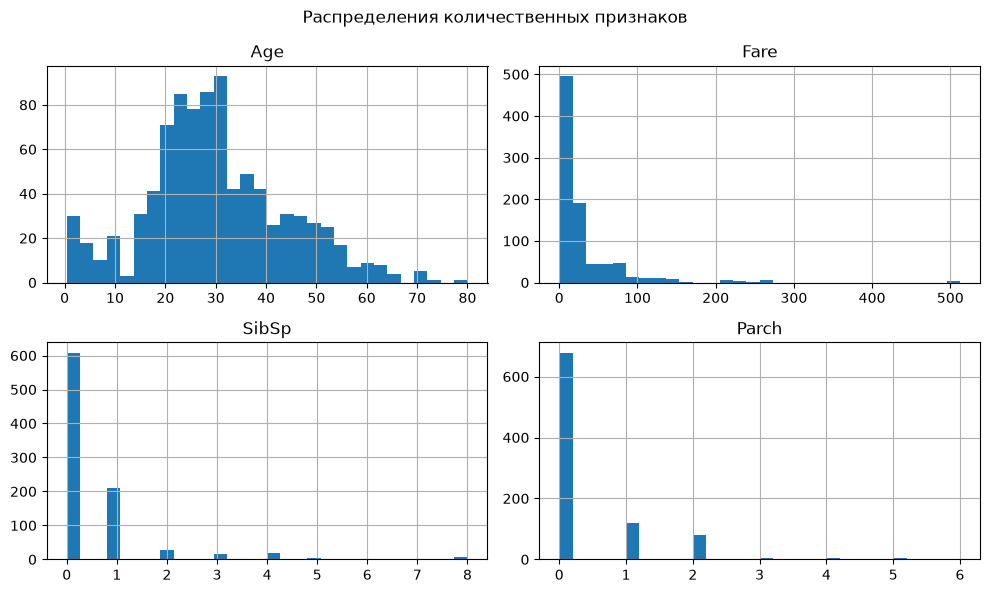

In [24]:
df_clean[["Age", "Fare", "SibSp", "Parch"]].hist(bins=30, figsize=(10, 6))
plt.suptitle("Распределения количественных признаков")
plt.tight_layout()
plt.show()

- Возраст распределен почти симметрично, с пиком в районе 20-30 лет и небольшим отдельным пиком у маленьких детей.
- Цена билета сильно скошена вправо почти все билеты дешевле 100.
- SibSp и Parch в основном нули, большинство ехали в одиночку.


## 4. Рассчитываем взаимосвязь между выживанием и другими факторами

Смотрим по очереди: возраст, класс билета, пол, размер семьи и цена билета. Для каждого фактора считаем или рисуем связь с выживаемостью и пробуем объяснить.

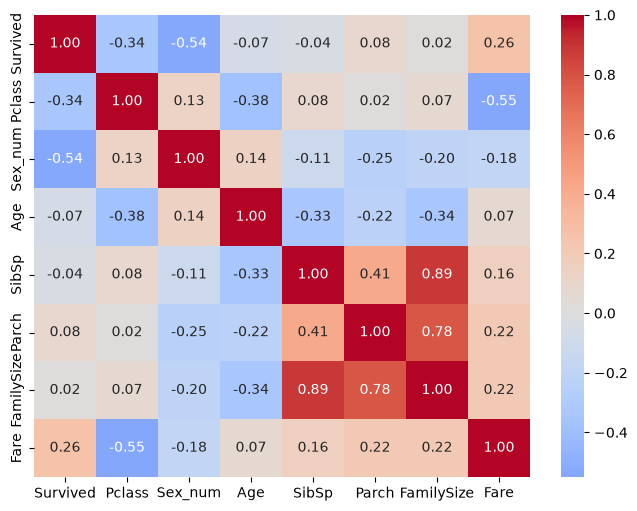

In [25]:
df_clean["Sex_num"] = (df_clean["Sex"] == "male").astype(int)
df_clean["FamilySize"] = df_clean["SibSp"] + df_clean["Parch"]

corr_cols = ["Survived", "Pclass", "Sex_num", "Age", "SibSp", "Parch", "FamilySize", "Fare"]
plt.figure(figsize=(8, 6))
sns.heatmap(df_clean[corr_cols].corr(), annot=True, fmt=".2f", cmap="coolwarm", center=0)
plt.show()

Сильнее всего с выживаемостью связаны пол (-0.54), класс билета (-0.34) и цена билета (0.26). У возраста и размера семьи корреляция около нуля, но это еще не значит, что связи нет. Разберем каждый фактор отдельно.

Еще видно, что цена билета и класс сильно связаны между собой (-0.55). Это надо помнить, когда будем смотреть на цену.

### 4.1. Возраст

Определим корреляцию между возрастом и выживанием.

In [26]:
r, p_value = stats.pearsonr(df_clean["Age"], df_clean["Survived"])
print(f"Коэффициент корреляции Пирсона: {r:.3f}, p-value: {p_value:.3f}")

Коэффициент корреляции Пирсона: -0.071, p-value: 0.034


Мы видим, что между переменными отрицательная связь на уровне -0.07. Это очень слабая связь, часто аналитики используют отсечку 0.3 по модулю, чтобы сказать, что корреляция выраженная.

При этом p-value равен 0.034, то есть формально корреляция статистически значима.

Но дело может быть даже не в том, что взаимосвязи почти нет, а в том, что в данном случае связь нелинейная. Коэффициент Пирсона, который мы посчитали выше, ловит только линейную связь, а Survived еще и бинарная переменная. Посмотрим, как это можно визуализировать:

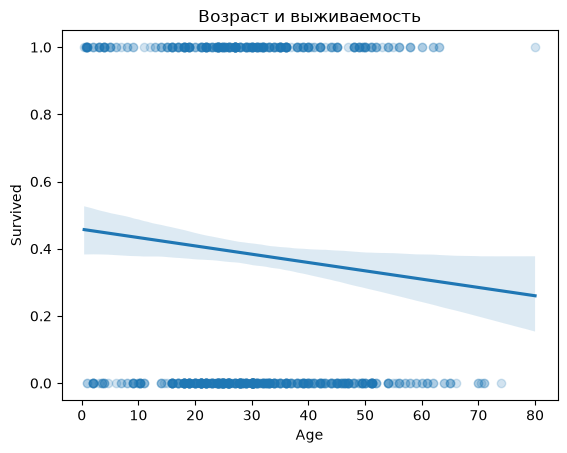

In [27]:
sns.regplot(data=df_clean, x="Age", y="Survived", scatter_kws={"alpha": 0.2})
plt.show()

Линия почти горизонтальная, это и есть -0.07. По такому графику мало что видно, поэтому разобьем возраст на группы.

<Axes: xlabel='Age_Group', ylabel='Survived'>

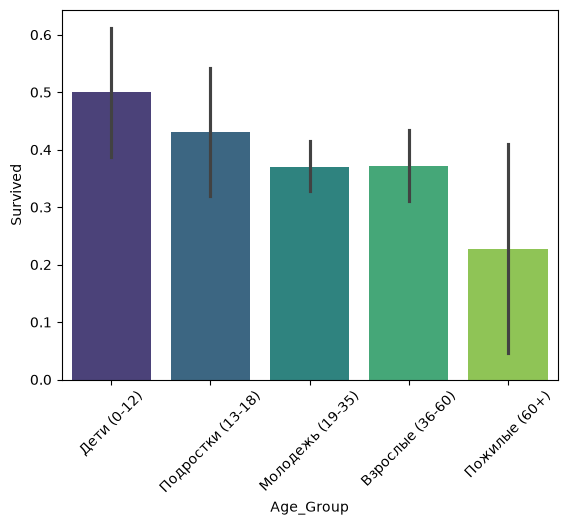

In [28]:
df_clean['Age_Group'] = pd.cut(df_clean['Age'],
                               bins=[0, 12, 18, 35, 60, 100],
                               labels=['Дети (0-12)', 'Подростки (13-18)', 'Молодежь (19-35)', 'Взрослые (36-60)', 'Пожилые (60+)'])
plt.xticks(rotation=45)
sns.barplot(data=df_clean, x='Age_Group', y='Survived', hue='Age_Group', palette='viridis', legend=False, dodge=False)

По барчарту можно заметить, что связь присутствует, но она нелинейная. Видно падение выживаемости при переходе от детей к молодежи, после чего показатель выходит на плато. Именно из-за этой нелинейной связи коэффициент Пирсона близок к нулю.

У пожилых выживаемость еще ниже, но их всего немного, поэтому делать выводы по такой группе я бы не стал.

Результат ожидаемый, при эвакуации действовало правило женщины и дети первыми, поэтому детей сажали в шлюпки в первую очередь.

### 4.2. Класс билета

<Axes: xlabel='Pclass', ylabel='Survived'>

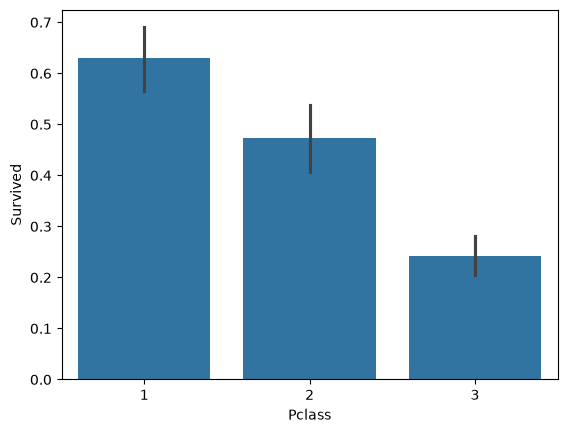

In [29]:
sns.barplot(data=df_clean, x='Pclass', y='Survived')

In [30]:
df_clean.groupby("Pclass")["Survived"].agg(выживаемость="mean", пассажиров="count").round(2)

,выживаемость,пассажиров
Pclass,,
1,0.63,216
2,0.47,184
3,0.24,491


In [31]:
correlation = df_clean["Pclass"].corr(df_clean["Survived"])
correlation

np.float64(-0.33848103596101464)

По графику можно утверждать, что от класса билета шансы на выживание сильно изменяются.

- Для пассажиров 1 класса выживаемость 63%.
- У пассажиров 2 класса уже 47%.
- Пассажиры 3 класса выживали только в 24% случаев.

Если посчитать коэффициент корреляции Пирсона, получится примерно -0.34 умеренная обратная линейная связь. С увеличением номера класса, шансы на спасение падают.

### 4.3. Пол

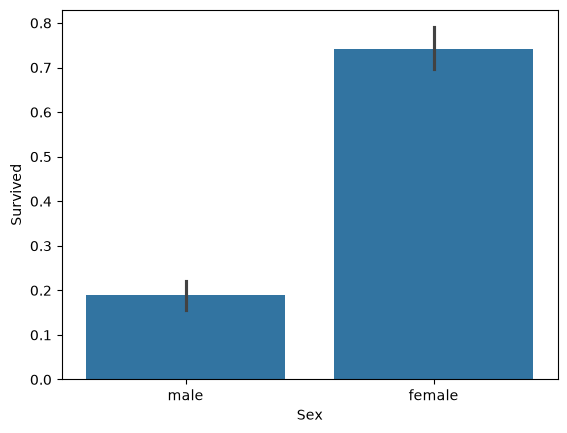

,выживаемость,пассажиров
Sex,,
female,0.74,314
male,0.19,577


In [32]:
sns.barplot(data=df_clean, x="Sex", y="Survived")
plt.show()

df_clean.groupby("Sex")["Survived"].agg(выживаемость="mean", пассажиров="count").round(2)

Это самый значимый фактор из всех выжило 74% женщин и только 19% мужчин. Объяснение то же, что и с детьми, женщин сажали в шлюпки первыми.

Разница огромная, но мужчин и женщин на борту было разное количество, и они могли отличаться по возрасту и классу. Поэтому значимость этой разницы отдельно проверим в разделе 5.

### 4.4. Размер семьи

В данных есть два столбца про родственников это SibSp (братья, сестры, супруги) и Parch (родители, дети). Сложим их в один признак FamilySize те сколько родственников было у пассажира на борту.

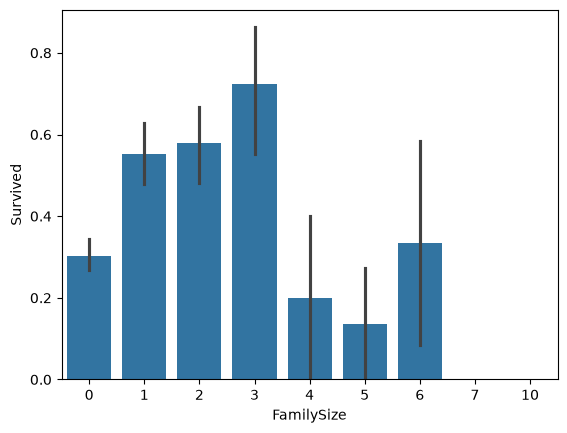

,выживаемость,пассажиров
FamilySize,,
0,0.30,537
1,0.55,161
2,0.58,102
3,0.72,29
4,0.20,15
5,0.14,22
6,0.33,12
7,0.00,6
10,0.00,7


In [33]:
family = df_clean.groupby("FamilySize")["Survived"].agg(выживаемость="mean", пассажиров="count").round(2)

sns.barplot(data=df_clean, x="FamilySize", y="Survived")
plt.show()
family

Корреляция размера семьи с выживаемостью почти нулевая (0.02), но связь есть, просто нелинейная, как и с возрастом:

- Одиночки выживали в 30% случаев, и их больше всего - 537 человек.
- С 1-3 родственниками шансы заметно выше, от 55% до 72%.
- В больших семьях, от 4 родственников, выживаемость снова падает. Но там группы от 6 до 22 человек, так что это скорее наблюдение.

Возможно одиночки это в основном мужчины, а небольшие семьи это женщины и дети, которых сажали в шлюпки вместе. Большой семье сложнее собраться и вместе попасть в одну шлюпку.

### 4.5. Цена билета

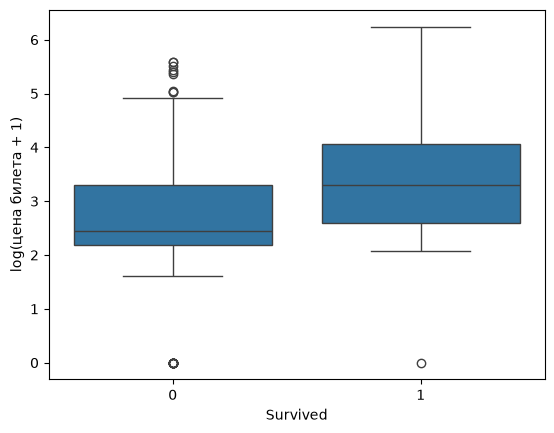

In [34]:
sns.boxplot(data=df_clean, x="Survived", y=np.log1p(df_clean["Fare"]))
plt.ylabel("log(цена билета + 1)")
plt.show()

In [35]:
#медианная цена билета у погибших и выживших
df_clean.groupby("Survived")["Fare"].median()

Survived
0    10.5
1    26.0
Name: Fare, dtype: float64

In [36]:
# цена билета и выживаемость внутри каждого класса
df_clean.groupby("Pclass").apply(
    lambda g: pd.Series({
        "медианная цена": g["Fare"].median(),
        "корреляция цены с выживаемостью": g["Fare"].corr(g["Survived"]),
    }),
    include_groups=False,
).round(2)

,медианная цена,корреляция цены с выживаемостью
Pclass,,
1,60.29,0.19
2,14.25,0.10
3,8.05,0.00


Медианная цена билета у выживших 26, у погибших 10.5, разница больше чем в два раза.

Но цена почти полностью определяется классом медиана в 1 классе 60.29, во 2 - 14.25, в 3 - 8.05. А если смотреть внутри одного класса, связь цены с выживаемостью слабая: 0.19 в 1 классе, 0.10 во 2 и нулевая в 3.

То есть цена билета сама по себе почти ничего не добавляет. Это тот же класс, только выраженный в деньгах.

## 5. Оцениваем статистическую значимость различий

В прошлом разделе самая большая разница была по полу. Проверим, что она статистически значима.
### 5.1. Пол

Чтобы ответить на вопрос, есть ли статистически значимые различия в вероятности выжить среди мужчин и женщин, используем Z-тест для пропорций: у нас две группы, и в каждой мы сравниваем долю выживших.

- H0: доли выживших среди мужчин и женщин равны
- H1: доли различаются
- уровень значимости 5%

In [37]:
females = df_clean[df_clean["Sex"] == "female"]["Survived"]
males = df_clean[df_clean["Sex"] == "male"]["Survived"]

z_stat, p_value = proportions_ztest(count=[females.sum(), males.sum()],
                                    nobs=[females.count(), males.count()])
print(f"Выживаемость женщин: {females.mean():.1%}, мужчин: {males.mean():.1%}")
print(f"Z-статистика: {z_stat:.2f}")
print(f"p-value: {p_value:.2e}")

Выживаемость женщин: 74.2%, мужчин: 18.9%
Z-статистика: 16.22
p-value: 3.71e-59


Полученное значение p-value стремится к нулю, что гораздо ниже стандартного уровня значимости альфа 5%. Поэтому мы отвергаем нулевую гипотезу, что разницы в выживаемости мужчин и женщин на Титанике нет. Это значит, что различия в вероятности выжить между мужчинами и женщинами статистически значимы.

### 5.2. Два фактора сразу: пол и возраст

Мы увидели, что женщины выживали намного чаще. Но могла ли быть ситуация, что мужчины на борту просто были старше, и дело не в поле, а в возрасте? Проверим.

In [38]:
df_clean.groupby("Sex")["Age"].agg(["mean", "median"]).round(1)

,mean,median
Sex,,
female,27.3,26.0
male,31.4,30.0


Мужчины действительно в среднем старше на 4 года. Посмотрим на выживаемость по полу внутри каждой возрастной группы.

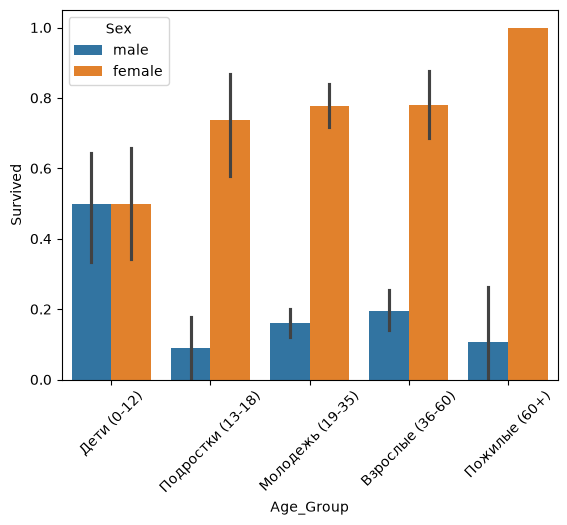

mean        count     
Sex               female  male female male
Age_Group                                 
Дети (0-12)         0.50  0.50     38   42
Подростки (13-18)   0.74  0.09     38   34
Молодежь (19-35)    0.78  0.16    162  313
Взрослые (36-60)    0.78  0.20     73  169
Пожилые (60+)       1.00  0.11      3   19

In [39]:
sns.barplot(data=df_clean, x="Age_Group", y="Survived", hue="Sex")
plt.xticks(rotation=45)
plt.show()

df_clean.pivot_table(index="Age_Group", columns="Sex", values="Survived", aggfunc=["mean", "count"], observed=True).round(2)

Во всех группах старше 12 лет разница между полами огромная: у женщин 74-78%, у мужчин 9-20%. Значит дело именно в поле, а не в том, что мужчины старше. (В группе 60+ всего 3 женщины, на нее не смотрим.)

А вот у детей разницы нет совсем: мальчики и девочки выживали одинаково, по 50%. То есть мальчика до 12 лет спасали как ребенка, а не как мужчину.

Проверим это тестом. Берем только мужчин и сравниваем детей со всеми остальными.

In [40]:
men = df_clean[df_clean["Sex"] == "male"]
boys = men[men["Age"] <= 12]["Survived"]
adult_men = men[men["Age"] > 12]["Survived"]

z_stat, p_value = proportions_ztest(count=[boys.sum(), adult_men.sum()],
                                    nobs=[boys.count(), adult_men.count()])
print(f"Мальчики до 12 лет: {boys.mean():.0%}, мужчины: {adult_men.mean():.0%}")
print(f"Z-статистика: {z_stat:.2f}, p-value: {p_value:.2e}")

Мальчики до 12 лет: 50%, остальные мужчины: 16%
Z-статистика: 5.35, p-value: 8.85e-08


Разница значима, мальчики выживали в 50% случаев, остальные мужчины в 16%.

Получается, что пол и возраст это два отдельных эффекта, и это хорошо ложится на правило женщины и дети первыми.

### 5.3. Два фактора сразу: пол и класс

Такая же проверка для класса возможно, женщин просто было больше в 1 классе

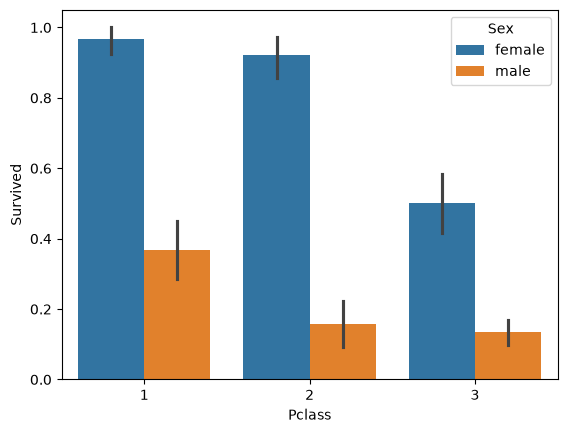

Sex,female,male
Pclass,,
1,0.97,0.37
2,0.92,0.16
3,0.50,0.14


In [41]:
sns.barplot(data=df_clean, x="Pclass", y="Survived", hue="Sex")
plt.show()

df_clean.pivot_table(index="Pclass", columns="Sex", values="Survived", aggfunc="mean").round(2)

Разница между полами сохраняется внутри каждого класса. При этом женщина из 3 класса выживала чаще (50%), чем мужчина из 1 класса (37%). То есть пол здесь важнее класса.

Чтобы оценить все факторы одновременно, построим логистическую регрессию. Она показывает влияние каждого фактора при фиксированных остальных.

In [42]:
model = smf.logit("Survived ~ C(Sex) + C(Pclass) + Age", data=df_clean).fit(disp=0)
pd.DataFrame({"коэффициент": model.params, "p-value": model.pvalues}).round(3)

,коэффициент,p-value
Intercept,3.415,0.0
C(Sex)[T.male],-2.550,0.0
C(Pclass)[T.2],-1.120,0.0
C(Pclass)[T.3],-2.362,0.0
Age,-0.029,0.0


У всех факторов коэффициенты отрицательные и значимые (p-value меньше 0.05). Это значит, что шансы выжить снижают: мужской пол, 2 и 3 класс по сравнению с 1 и возраст.

Интересно, что возраст сам по себе давал корреляцию всего -0.07, а когда пол и класс учтены, его влияние становится заметнее.

## 6. Итоговые выводы

- Пол - самый сильный фактор. Выжило 74% женщин и 19% мужчин, разница значима и сохраняется внутри каждого класса и каждой возрастной группы старше 12 лет.
- Класс билета - второй по силе. В 1 классе выжило 63%, во 2 - 47%, в 3 - 24%.
- Возраст влияет нелинейно, поэтому корреляция Пирсона всего -0.07. Дети до 12 лет выживали в 50% случаев, причем мальчики и девочки одинаково.
- Размер семьи тоже влияет нелинейно, хуже всего одиночкам (30%), лучше всего тем, у кого на борту было 1-3 родственника.
- Цена билета связана с выживаемостью, но в основном через класс билета.
- Данные. Номер каюты удален, тк 77% пропусков. Возраст заполнен через KNN без использования целевой переменной. Выбросы в цене билета оставлены, это реальные билеты 1 класса.

Если смотреть на пассажиров как на клиентскую базу, то по ключевой метрике сильнее всего различаются сегменты по полу и классу. Самый сильный сегмент - женщины 1 и 2 класса (больше 90% выживших), самый слабый - мужчины 2 и 3 класса (около 15%).